<a href="https://colab.research.google.com/github/Syahara31/Pengolahan-Citra-Digital-Praktikum/blob/main/Praktikum_pcd.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

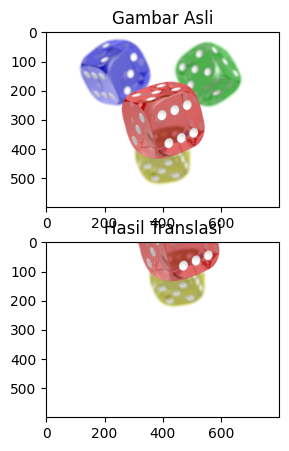

In [32]:
import imageio.v3 as img
import numpy as np
import matplotlib.pyplot as plt

def Translasi(image, shiftX, shiftY):
    imgTranslasi = np.roll(image, shift=shiftY, axis=0) # Geser vertikal
    imgTranslasi = np.roll(imgTranslasi, shift=shiftX, axis=1) # Geser horizontal

    # Mengisi bagian yang kosong dengan warna hitam (0)
    if shiftY > 0:
        imgTranslasi[:shiftY, :] = 0 # Bagian atas jika geser ke bawah
    elif shiftY < 0:
        imgTranslasi[shiftY:, :] = 0 # Bagian bawah jika geser ke atas
    if shiftX > 0:
        imgTranslasi[:, :shiftX] = 0 # Bagian kiri jika geser ke kanan
    elif shiftX < 0:
        imgTranslasi[:, shiftX:] = 0 # Bagian kanan jika geser ke kiri

    return imgTranslasi

# Membaca gambar (sesuaikan path dengan lokasi file Anda)
image = img.imread("/content/Screenshot 2026-10-29 08.32.50.png")

imgResult = Translasi(image, shiftX=50, shiftY=-300)

plt.figure(figsize=(5,5))
plt.subplot(2, 1, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(2, 1, 2)
plt.title("Hasil Translasi")
plt.imshow(imgResult)

plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

/tmp/ipykernel_5652/3990103850.py:6: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread(path)


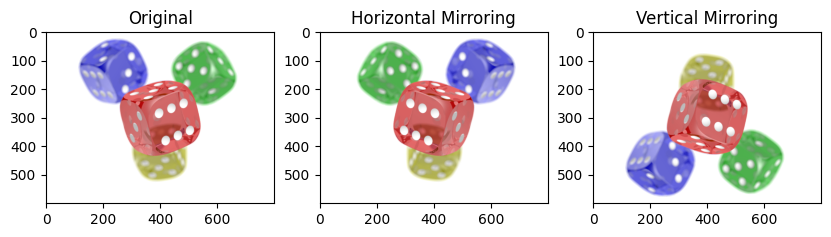

In [16]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

path = '/content/Screenshot 2026-10-29 08.32.50.png'
image = img.imread(path)

height, width = image.shape[:2]
horizontal = np.zeros_like(image)
vertical = np.zeros_like(image)

# Mirroring Horizontal
for y in range(height):
    for x in range(width):
        horizontal[y, x] = image[y, width - 1 - x]

# Mirroring Vertikal
for y in range(height):
    for x in range(width):
        vertical[y, x] = image[height - 1 - y, x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.title("Original")
plt.imshow(image)

plt.subplot(1, 3, 2)
plt.title("Horizontal Mirroring")
plt.imshow(horizontal)

plt.subplot(1, 3, 3)
plt.title("Vertical Mirroring")
plt.imshow(vertical)

plt.show()

/tmp/ipykernel_5652/3551119499.py:36: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('/content/Screenshot 2026-10-29 08.32.50.png')


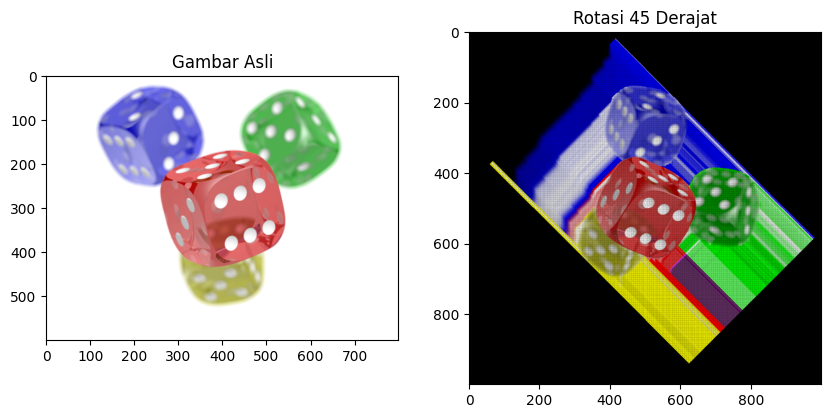

In [20]:
import imageio as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImage(image, degree):
    # Jika gambar memiliki channel RGBA (4 channel), ambil 3 channel pertama (RGB) saja
    if image.ndim == 3 and image.shape[2] == 4:
        image = image[:, :, :3]

    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    max_dim = int(np.sqrt(height**2 + width**2))

    # Menyesuaikan channel secara dinamis
    channels = image.shape[2] if image.ndim == 3 else 1
    if image.ndim == 3:
        outputImage = np.zeros((max_dim, max_dim, channels), dtype=image.dtype)
    else:
        outputImage = np.zeros((max_dim, max_dim), dtype=image.dtype)

    centerY, centerX = max_dim // 2, max_dim // 2

    for y in range(-height // 2, height // 2):
        for x in range(-width // 2, width // 2):
            newX = int(cos_deg * x - sin_deg * y) + centerX
            newY = int(sin_deg * x + cos_deg * y) + centerY

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y + height // 2, x + width // 2]

    return outputImage

# Membaca gambar
image = img.imread('/content/Screenshot 2026-10-29 08.32.50.png')

rotated_image = rotateImage(image, 45)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Rotasi 45 Derajat")
plt.imshow(rotated_image)

plt.show()

/tmp/ipykernel_5652/1629837033.py:34: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('/content/Screenshot 2026-10-29 08.32.50.png')


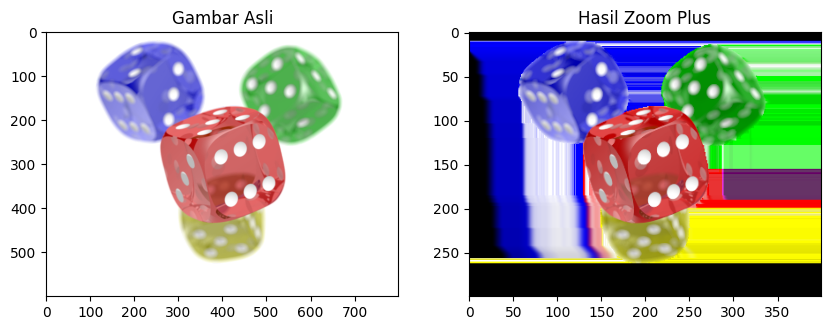

In [23]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

def zoomPlus(image, factor):
    # Jika gambar memiliki 4 channel (RGBA), ambil 3 channel pertama (RGB) saja
    if image.ndim == 3 and image.shape[2] == 4:
        image = image[:, :, :3]

    height, width = image.shape[:2]
    new_height = int(height / factor)
    new_width = int(width / factor)

    # Menyesuaikan channel secara dinamis
    channels = image.shape[2] if image.ndim == 3 else 1
    if image.ndim == 3:
        imgZoom = np.zeros((new_height, new_width, channels), dtype=image.dtype)
    else:
        imgZoom = np.zeros((new_height, new_width), dtype=image.dtype)

    for y in range(new_height):
        for x in range(new_width):
            ori_y = int(y * factor)
            ori_x = int(x * factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom

# 1. Read Image
image = img.imread('/content/Screenshot 2026-10-29 08.32.50.png')
skala = 2.0

# 2. Process Zoom
imgZoom = zoomPlus(image, skala)

# 3. Save Output (Gunakan nama file baru agar tidak menimpa gambar asli)
img.imwrite("/content/hasil_zoom.png", imgZoom)

# 4. Display Result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Hasil Zoom Plus")
plt.imshow(imgZoom)

plt.show()

/tmp/ipykernel_5652/1511553969.py:6: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread(path)


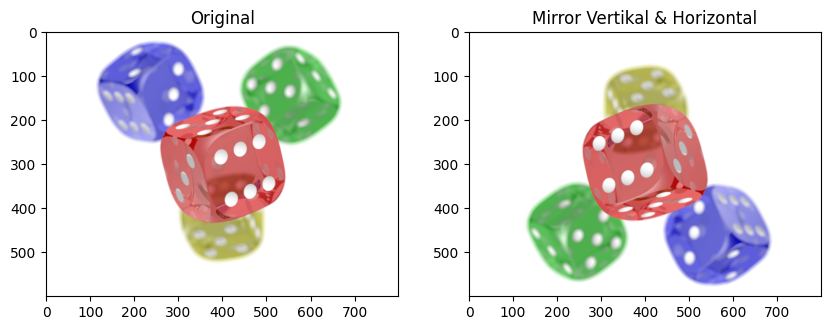

In [24]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

path = '/content/Screenshot 2026-10-29 08.32.50.png'
image = img.imread(path)

height, width = image.shape[:2]
both_mirror = np.zeros_like(image)

# Mirroring Vertikal & Horizontal secara bersamaan
for y in range(height):
    for x in range(width):
        both_mirror[y, x] = image[height - 1 - y, width - 1 - x]

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Original")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Mirror Vertikal & Horizontal")
plt.imshow(both_mirror)

plt.show()

/tmp/ipykernel_5652/958974286.py:29: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('/content/Screenshot 2026-10-29 08.32.50.png')


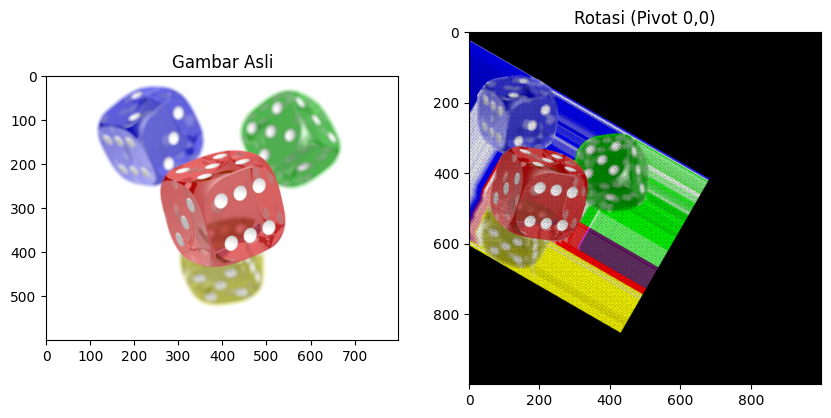

In [27]:
import imageio as img
import numpy as np
import matplotlib.pyplot as plt

def rotateImagePivot00(image, degree):
    # Jika gambar memiliki channel RGBA (4 channel), ambil 3 channel pertama (RGB) saja
    if image.ndim == 3 and image.shape[2] == 4:
        image = image[:, :, :3]

    radian_deg = np.radians(degree)
    cos_deg, sin_deg = np.cos(radian_deg), np.sin(radian_deg)

    height, width = image.shape[:2]
    # Matriks output menggunakan dimensi maksimum diagonal gambar
    max_dim = int(np.sqrt(height**2 + width**2))
    outputImage = np.zeros((max_dim, max_dim, 3), dtype=image.dtype)

    for y in range(height):
        for x in range(width):
            # Rotasi dengan pivot langsung di titik (0,0)
            newX = int(cos_deg * x - sin_deg * y)
            newY = int(sin_deg * x + cos_deg * y)

            if 0 <= newX < max_dim and 0 <= newY < max_dim:
                outputImage[newY, newX] = image[y, x]

    return outputImage

image = img.imread('/content/Screenshot 2026-10-29 08.32.50.png')

rotated_image = rotateImagePivot00(image, 30)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Rotasi (Pivot 0,0)")
plt.imshow(rotated_image)

plt.show()

/tmp/ipykernel_5652/171849675.py:27: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = img.imread('/content/Screenshot 2026-10-29 08.32.50.png')


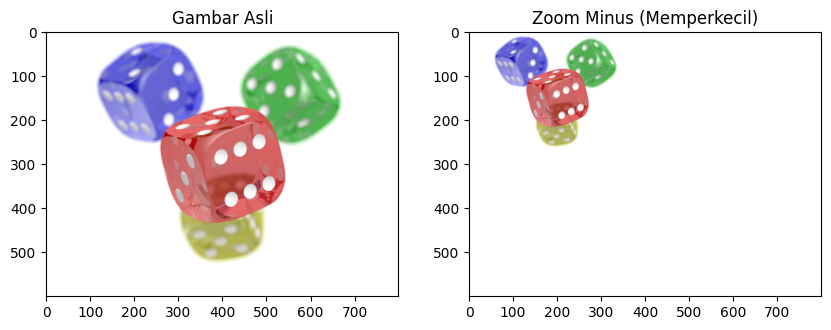

In [28]:
import numpy as np
import imageio as img
import matplotlib.pyplot as plt

def zoomMinus(image, factor):
    height, width = image.shape[:2]
    # Kanvas tetap berukuran sama dengan citra asli
    imgZoom = np.zeros_like(image)

    # Menentukan dimensi baru yang diperkecil
    new_height = int(height / factor)
    new_width = int(width / factor)

    # Mengisi piksel pada area yang diperkecil
    for y in range(new_height):
        for x in range(new_width):
            ori_y = int(y * factor)
            ori_x = int(x * factor)

            ori_y = min(ori_y, height - 1)
            ori_x = min(ori_x, width - 1)

            imgZoom[y, x] = image[ori_y, ori_x]

    return imgZoom

image = img.imread('/content/Screenshot 2026-10-29 08.32.50.png')
skala = 2.0  # Faktor 2.0 memperkecil gambar menjadi 1/2 ukuran asli

imgResult = zoomMinus(image, skala)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Gambar Asli")
plt.imshow(image)

plt.subplot(1, 2, 2)
plt.title("Zoom Minus (Memperkecil)")
plt.imshow(imgResult)

plt.show()